# E3 Explore Whisper embeddings without accent labels

This notebook completes the proposal's unsupervised study. We ask whether fixed Whisper features form groups that align with the known accent labels. We use PCA and K-means without labels. We show PCA and UMAP maps, then compare clusters with accent and source metadata.

**Scope:** use only the original training and validation clips, called the development set. The 6,119 study test clips do not enter any fit, plot, or score in this run. This is an exploratory analysis of development data, not a test of classification accuracy.

An earlier version explored all 40,000 clips, including the study test set. That completed notebook is preserved in `notebooks/archive/E3_01_unsupervised_learning_all40000_20261028.ipynb`; its results remain in `outputs/e3`. Excluding test clips now does not make the earlier study test untouched again.

We reuse the verified frozen `openai/whisper-base.en` cache. We do not run or train Whisper. Cluster overlap is a valid result. We do not tune the classifier from these plots or scores.

## 1 Check the environment and fixed settings

Run all cells in order with the **Singlish final fusion Python 3.14** kernel. This notebook uses installed packages and records their versions. It does not install or update packages during execution.

The settings below are fixed for this revision before its label tables are calculated. They are not a claim of a preregistered study: the earlier all-clip result has already been viewed. We keep **50 PCA components** from that study. This is a separate analysis from fusion's PCA32 branch. K-means uses two clusters to examine the proposal's two-group question. Setting two clusters does not prove that the data naturally contain two groups.

In [1]:
from pathlib import Path
from collections import Counter
import datetime
import hashlib
import importlib.metadata
import json
import platform
import time

import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import umap
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

%matplotlib inline

working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (working_dir, *working_dir.parents)
     if (folder / 'notebooks').is_dir() and (folder / 'data').is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from the singlish-whisper project or its notebooks folder.')

E2_OUTPUT = PROJECT_ROOT / 'outputs/frozen_whisper_40000_20261028'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/e3_development_20261028'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR = OUTPUT_DIR / 'charts'
CHART_DIR.mkdir(exist_ok=True)
RESULT_PATH = PROJECT_ROOT / 'results/E3_UNSUPERVISED_DEVELOPMENT_20261028.md'

SETTINGS = {
    'analysis_splits': ['train', 'validation'],
    'pca_components': 50,
    'pca_solver': 'full',
    'clusters': 2,
    'kmeans_n_init': 10,
    'seed': 42,
    'stability_seeds': [7, 19],
    'silhouette_max_clips': 5000,
    'umap_neighbors': 15,
    'umap_min_dist': 0.1,
    'umap_init': 'random',
    'speaker_mean_check': True,
}
settings_json = json.dumps(SETTINGS, sort_keys=True, indent=2)
settings_sha256 = hashlib.sha256(settings_json.encode()).hexdigest()
packages = {name: importlib.metadata.version(name) for name in [
    'numpy', 'pandas', 'scipy', 'scikit-learn', 'umap-learn', 'numba',
    'matplotlib', 'joblib', 'nbformat', 'nbclient',
]}
started_utc = datetime.datetime.now(datetime.timezone.utc).isoformat()
run_started = time.perf_counter()
timing = []
print('Project:', PROJECT_ROOT)
print('Output:', OUTPUT_DIR)
print('Python:', platform.python_version())
print('Packages:', json.dumps(packages, sort_keys=True))
print('Fixed settings:', settings_json)
(OUTPUT_DIR / 'protocol.json').write_text(json.dumps({
    'settings': SETTINGS, 'settings_sha256': settings_sha256,
    'started_utc': started_utc, 'packages': packages,
    'scope': 'Development-only exploratory analysis; prior all-clip exploration exists.',
}, indent=2) + '\n')

/home/mh/miniconda3/envs/singlish-py314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project: /home/mh/nusproj/singlish-whisper
Output: /home/mh/nusproj/singlish-whisper/outputs/e3_development_20261028
Python: 3.14.7
Packages: {"joblib": "1.6.0", "matplotlib": "3.11.2", "nbclient": "0.11.0", "nbformat": "5.11.1", "numba": "0.67.0", "numpy": "2.5.3", "pandas": "2.3.3", "scikit-learn": "1.9.1", "scipy": "1.18.1", "umap-learn": "0.5.12"}
Fixed settings: {
  "analysis_splits": [
    "train",
    "validation"
  ],
  "clusters": 2,
  "kmeans_n_init": 10,
  "pca_components": 50,
  "pca_solver": "full",
  "seed": 42,
  "silhouette_max_clips": 5000,
  "speaker_mean_check": true,
  "stability_seeds": [
    7,
    19
  ],
  "umap_init": "random",
  "umap_min_dist": 0.1,
  "umap_neighbors": 15
}


897

## 2 Verify the cache and original speaker splits

E2 supplies a verified cache, an audio audit, and the original manifest. Check the cache hash. Match each embedding to its clip ID, label, speaker ID, and split. Join by clip ID rather than assuming that two files have the same row order.

The manifest labels are checked for identity, then kept for later interpretation. No label or source metadata enters scaling, PCA, K-means, or UMAP. Test embeddings are loaded only as part of the cache audit and are removed before analysis.

In [2]:
def sha256_file(path):
    with Path(path).open('rb') as file:
        return hashlib.file_digest(file, 'sha256').hexdigest()

required_files = ['whisper_provenance.json', 'dataset_manifest.csv', 'dataset_identity.json', 'audio_audit.json']
for name in required_files:
    if not (E2_OUTPUT / name).is_file():
        raise FileNotFoundError(f'Missing E2 record: {E2_OUTPUT / name}. Complete the final 40k E2 audit first.')

provenance = json.loads((E2_OUTPUT / 'whisper_provenance.json').read_text())
identity = json.loads((E2_OUTPUT / 'dataset_identity.json').read_text())
audio_audit = json.loads((E2_OUTPUT / 'audio_audit.json').read_text())
cache_path = Path(provenance['cache_path'])
if not cache_path.is_absolute():
    cache_path = PROJECT_ROOT / cache_path
cache_sha256 = sha256_file(cache_path)
if cache_sha256 != provenance['cache_file_sha256']:
    raise ValueError('The feature cache differs from the cache verified by E2.')
if provenance['dataset_id'] != identity['dataset_id']:
    raise ValueError('The E2 provenance and dataset identity differ.')
if not provenance['frozen'] or not provenance['decoded_audio_matches_reference']:
    raise ValueError('Need the frozen encoder cache with a passed decoded-audio match.')
if provenance['model'] != 'openai/whisper-base.en':
    raise ValueError('Unexpected encoder model.')
if audio_audit['status'] != 'passed' or audio_audit['decoded_hash_matches'] != 40000:
    raise ValueError('The E2 audio audit is incomplete.')

manifest_path = E2_OUTPUT / 'dataset_manifest.csv'
manifest = pd.read_csv(manifest_path, dtype={
    'clip_id': str, 'speaker_group': str, 'source': str, 'split': str, 'label': np.int64,
})
if len(manifest) != 40000 or not manifest['clip_id'].is_unique:
    raise ValueError('The final manifest must have 40,000 unique clip IDs.')
original_split_path = cache_path.parents[2] / 'e1_feature_study_accent_40000/speaker_splits.csv'
original_split_sha256 = sha256_file(original_split_path)
if original_split_sha256 != identity['original_split_sha256']:
    raise ValueError('The original E1 speaker split file differs from the E2 reference.')
original_splits = pd.read_csv(original_split_path, dtype={'clip_id': str, 'speaker_group': str})
if not original_splits['clip_id'].is_unique or set(original_splits['clip_id']) != set(manifest['clip_id']):
    raise ValueError('Original E1 and E2 manifests have different clip IDs.')
original_by_id = original_splits.set_index('clip_id').loc[manifest['clip_id']]
for field in ['split', 'label', 'speaker_group']:
    if not np.array_equal(original_by_id[field].to_numpy(), manifest[field].to_numpy()):
        raise ValueError(f'Original E1 and E2 {field} values differ.')
with np.load(cache_path, allow_pickle=False) as cache:
    required = {'features', 'clip_ids', 'labels', 'groups', 'provenance_json'}
    if not required.issubset(cache.files):
        raise ValueError(f'Missing cache keys: {sorted(required - set(cache.files))}')
    cached_features = cache['features'].astype(np.float32)
    cached_ids = cache['clip_ids'].astype(str)
    cached_labels = cache['labels'].astype(np.int64)
    cached_groups = cache['groups'].astype(str)
    cache_provenance = json.loads(str(cache['provenance_json'].item()))

if cached_features.shape != (40000, 512) or not np.isfinite(cached_features).all():
    raise ValueError('Need 40,000 finite 512-value embeddings.')
if len(set(cached_ids)) != 40000 or set(cached_ids) != set(manifest['clip_id']):
    raise ValueError('Cache and manifest clip IDs differ.')
metadata = manifest.set_index('clip_id').loc[cached_ids].reset_index()
if not np.array_equal(cached_labels, metadata['label'].to_numpy()):
    raise ValueError('Cache and manifest labels differ.')
if not np.array_equal(cached_groups, metadata['speaker_group'].to_numpy()):
    raise ValueError('Cache and manifest speaker IDs differ.')
if cache_provenance['model'] != provenance['model']:
    raise ValueError('The cache encoder model differs from E2.')
if set(metadata['split']) != {'train', 'validation', 'test'}:
    raise ValueError('Unexpected study splits.')
if metadata.groupby('speaker_group')['split'].nunique().max() != 1:
    raise ValueError('A speaker occurs in more than one study split.')
if metadata.groupby('speaker_group')['label'].nunique().max() != 1:
    raise ValueError('A speaker has inconsistent class labels.')
if metadata.groupby('speaker_group')['source'].nunique().max() != 1:
    raise ValueError('A speaker has inconsistent source metadata.')

development_mask = metadata['split'].isin(SETTINGS['analysis_splits']).to_numpy()
development = metadata.loc[development_mask].reset_index(drop=True)
excluded_test = metadata.loc[~development_mask].reset_index(drop=True)
X = cached_features[development_mask].copy()
if len(development) != 33881 or len(excluded_test) != 6119 or set(excluded_test['split']) != {'test'}:
    raise ValueError('The original development and test counts do not match.')
clip_overlap = set(development['clip_id']) & set(excluded_test['clip_id'])
speaker_overlap = set(development['speaker_group']) & set(excluded_test['speaker_group'])
if clip_overlap or speaker_overlap:
    raise ValueError('Development and excluded test data overlap.')
assert len(X) == len(development) and len(X) == int(development_mask.sum())
del cached_features, cached_ids, cached_labels, cached_groups, metadata

split_summary = development.groupby('split').agg(
    clips=('clip_id', 'size'), speakers=('speaker_group', 'nunique')
).reset_index()
split_summary.to_csv(OUTPUT_DIR / 'included_splits.csv', index=False)
development[['clip_id', 'speaker_group', 'source', 'split', 'label']].to_csv(
    OUTPUT_DIR / 'development_manifest.csv', index=False)
excluded_test[['clip_id', 'speaker_group', 'split']].to_csv(OUTPUT_DIR / 'excluded_test_ids.csv', index=False)

audit = {
    'status': 'passed', 'cache_sha256': cache_sha256,
    'manifest_sha256': sha256_file(manifest_path),
    'original_split_path': str(original_split_path), 'original_split_sha256': original_split_sha256,
    'dataset_id': identity['dataset_id'], 'audio_id': provenance['audio_id'],
    'encoder_revision': provenance['resolved_revision'],
    'development_clips': len(development), 'development_speakers': development['speaker_group'].nunique(),
    'excluded_test_clips': len(excluded_test), 'excluded_test_speakers': excluded_test['speaker_group'].nunique(),
    'fit_test_clip_overlap': len(clip_overlap), 'fit_test_speaker_overlap': len(speaker_overlap),
    'fit_clip_ids_sha256': hashlib.sha256('\n'.join(sorted(development['clip_id'])).encode()).hexdigest(),
    'audio_redecoded_in_e3': False, 'encoder_rerun_in_e3': False,
    'earlier_all_clip_exploration': True,
}
(OUTPUT_DIR / 'input_audit.json').write_text(json.dumps(audit, indent=2, default=int) + '\n')
print('Input audit passed. Test clips are excluded from every analysis below.')
display(split_summary)
print('Development:', X.shape, 'with', development['speaker_group'].nunique(), 'speakers')
print('Excluded test:', len(excluded_test), 'clips;', len(speaker_overlap), 'shared speakers')

Input audit passed. Test clips are excluded from every analysis below.


,split,clips,speakers
0,train,27797,6939
1,validation,6084,1504


Development: (33881, 512) with 8443 speakers
Excluded test: 6119 clips; 0 shared speakers


## 3 Fit PCA and K-means without labels

Each clip has equal weight in the primary analysis. `StandardScaler` fits only the development embeddings. PCA retains 50 components. K-means fits those 50-dimensional values, not the two-dimensional plot.

The function below accepts only an embedding matrix. It has no accent-label or source argument. Ten initializations reduce dependence on one random start. No score is used to select a PCA width, cluster count, or seed.

In [3]:
def fit_unsupervised(matrix):
    if matrix.shape[0] <= SETTINGS['pca_components']:
        raise ValueError('Too few observations for the fixed PCA width.')
    scaler = StandardScaler()
    scaled = scaler.fit_transform(matrix)
    pca = PCA(n_components=SETTINGS['pca_components'], svd_solver=SETTINGS['pca_solver'])
    reduced = pca.fit_transform(scaled)
    kmeans = KMeans(n_clusters=SETTINGS['clusters'], n_init=SETTINGS['kmeans_n_init'],
                    random_state=SETTINGS['seed'])
    clusters = kmeans.fit_predict(reduced)
    assert int(scaler.n_samples_seen_) == len(matrix)
    assert pca.n_samples_ == len(matrix)
    return scaler, pca, reduced, kmeans, clusters

phase_started = time.perf_counter()
scaler, pca, X_reduced, kmeans, clusters = fit_unsupervised(X)
timing.append({'stage': 'development_scaling_pca_kmeans', 'seconds': time.perf_counter() - phase_started})
if len(np.unique(clusters)) != 2:
    raise ValueError('K-means did not form two nonempty clusters.')
variance_retained = float(pca.explained_variance_ratio_.sum())
print('Observations used for fitting:', len(X))
print('PCA dimensions:', X_reduced.shape[1])
print('PCA variance retained:', f'{variance_retained:.2%}')
print('Cluster sizes:', dict(sorted(Counter(int(c) for c in clusters).items())))

Observations used for fitting: 33881
PCA dimensions: 50
PCA variance retained: 59.68%
Cluster sizes: {0: 25416, 1: 8465}


## 4 Measure separation and sensitivity to the starting seed

The silhouette score measures geometric separation. It does not measure accent accuracy. For this dataset, use a fixed random sample of 5,000 development clips to limit the pairwise-distance cost. Record the sampled clip IDs.

Two additional seeds repeat K-means on the same scaled PCA representation. Their adjusted Rand index (ARI) compares cluster assignments with the primary run, without accent labels. This checks sensitivity to initialization. It does not measure stability under new speakers or recording sources.

In [4]:
silhouette_rng = np.random.default_rng(SETTINGS['seed'])
silhouette_indices = np.sort(silhouette_rng.choice(
    len(X_reduced), min(SETTINGS['silhouette_max_clips'], len(X_reduced)), replace=False))
phase_started = time.perf_counter()
silhouette = float(silhouette_score(X_reduced[silhouette_indices], clusters[silhouette_indices]))
development.iloc[silhouette_indices][['clip_id']].to_csv(OUTPUT_DIR / 'silhouette_sample_ids.csv', index=False)
stability_rows = [{'seed': SETTINGS['seed'], 'ari_to_primary': 1.0,
                   'inertia': float(kmeans.inertia_), 'iterations': int(kmeans.n_iter_)}]
for seed in SETTINGS['stability_seeds']:
    alternative = KMeans(n_clusters=SETTINGS['clusters'], n_init=SETTINGS['kmeans_n_init'], random_state=seed)
    alternative_clusters = alternative.fit_predict(X_reduced)
    stability_rows.append({'seed': seed, 'ari_to_primary': float(adjusted_rand_score(clusters, alternative_clusters)),
                           'inertia': float(alternative.inertia_), 'iterations': int(alternative.n_iter_)})
stability = pd.DataFrame(stability_rows)
stability.to_csv(OUTPUT_DIR / 'initialization_stability.csv', index=False)
timing.append({'stage': 'silhouette_and_initialization_checks', 'seconds': time.perf_counter() - phase_started})
print('Silhouette:', f'{silhouette:.4f}', 'on', len(silhouette_indices), 'development clips')
display(stability)

Silhouette: 0.1272 on 5000 development clips


,seed,ari_to_primary,inertia,iterations
0,42,1.000000,9516438.0,18
1,7,1.000000,9516438.0,18
2,19,0.999874,9516436.0,20


## 5 Make PCA and UMAP maps without labels

PCA's first two components give a linear view of the fitted representation. UMAP gives a second two-dimensional display. It fits development PCA features only. Neither map uses accent labels or source metadata.

K-means does not use UMAP coordinates. UMAP islands do not establish distinct accents. Distances between distant islands are not exact distances between accents. Later figures use these same coordinates, so changes in color do not change the map.

UMAP coordinates: (33881, 2)


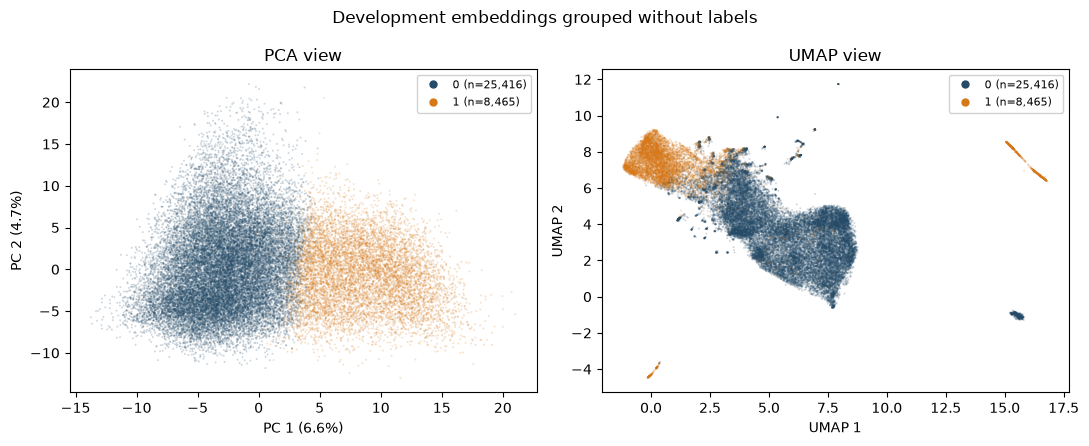

In [5]:
phase_started = time.perf_counter()
pca_xy = X_reduced[:, :2].copy()
umap_model = umap.UMAP(
    n_components=2, n_neighbors=SETTINGS['umap_neighbors'], min_dist=SETTINGS['umap_min_dist'],
    metric='euclidean', random_state=SETTINGS['seed'], init=SETTINGS['umap_init'], n_jobs=1,
)
umap_xy = umap_model.fit_transform(X_reduced)
timing.append({'stage': 'development_umap_display', 'seconds': time.perf_counter() - phase_started})
print('UMAP coordinates:', umap_xy.shape)

# One scatter call with shuffled draw order avoids drawing one entire group on top of another.
draw_order = np.random.default_rng(SETTINGS['seed']).permutation(len(X))
def draw_maps(categories, category_order, colors, title, filename):
    categories = np.asarray(categories).astype(str)
    category_order = [str(value) for value in category_order]
    codes = np.array([category_order.index(value) for value in categories])
    counts = Counter(categories)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    views = [
        (pca_xy, 'PCA view', f'PC 1 ({pca.explained_variance_ratio_[0]:.1%})',
         f'PC 2 ({pca.explained_variance_ratio_[1]:.1%})'),
        (umap_xy, 'UMAP view', 'UMAP 1', 'UMAP 2'),
    ]
    handles = [Line2D([], [], color=color, marker='o', linestyle='', markersize=5,
                      label=f'{name} (n={counts[name]:,})')
               for name, color in zip(category_order, colors)]
    for ax, (xy, name, x_label, y_label) in zip(axes, views):
        ax.scatter(xy[draw_order, 0], xy[draw_order, 1], c=codes[draw_order],
                   cmap=ListedColormap(colors), vmin=-0.5, vmax=len(category_order)-0.5,
                   s=2, alpha=0.22, linewidths=0, rasterized=True)
        ax.set(title=name, xlabel=x_label, ylabel=y_label)
        ax.legend(handles=handles, fontsize=8, loc='best', framealpha=0.9)
    fig.suptitle(title)
    fig.tight_layout()
    path = CHART_DIR / filename
    fig.savefig(path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path

cluster_figure = draw_maps(clusters, [0, 1], ['#254B68', '#D77818'],
    'Development embeddings grouped without labels', 'clusters.png')

## 6 Reveal accent labels and recording sources

Only now calculate agreement with the known accent labels. ARI is unchanged when cluster numbers are swapped. Approximately zero means chance-level agreement between the partitions; one means perfect agreement. It is not held-out classification accuracy.

All Singapore clips come from MNSC. Other sources supply non-Singapore clips. Source and class therefore remain confounded. Count both clips and distinct speakers. The same speaker can have clips in both clusters; do not add per-cluster speaker counts to estimate the total speaker count.

In [6]:
assignments = development[['clip_id', 'speaker_group', 'source', 'split', 'label']].copy()
assignments['cluster'] = clusters
assignments['known_label'] = assignments['label'].map({0: 'Non-Singapore', 1: 'Singapore'})
assignments['pc1'] = pca_xy[:, 0]
assignments['pc2'] = pca_xy[:, 1]
assignments['umap1'] = umap_xy[:, 0]
assignments['umap2'] = umap_xy[:, 1]
assignments.to_csv(OUTPUT_DIR / 'clip_assignments.csv', index=False)

cluster_labels = pd.crosstab(assignments['cluster'], assignments['known_label']).reindex(
    index=[0, 1], columns=['Non-Singapore', 'Singapore'], fill_value=0)
cluster_labels['total_clips'] = cluster_labels[['Non-Singapore', 'Singapore']].sum(axis=1)
cluster_labels['Singapore_share'] = cluster_labels['Singapore'] / cluster_labels['total_clips']
cluster_labels['distinct_speakers'] = assignments.groupby('cluster')['speaker_group'].nunique()
cluster_labels.to_csv(OUTPUT_DIR / 'cluster_label_counts.csv')
label_ari = float(adjusted_rand_score(assignments['label'], clusters))

source_order = sorted(assignments['source'].unique())
cluster_sources = pd.crosstab(assignments['source'], assignments['cluster']).reindex(
    index=source_order, columns=[0, 1], fill_value=0)
cluster_sources.to_csv(OUTPUT_DIR / 'cluster_source_counts.csv')
source_details = assignments.groupby(['source', 'cluster']).agg(
    clips=('clip_id', 'size'), speakers=('speaker_group', 'nunique')).reset_index()
source_details.to_csv(OUTPUT_DIR / 'cluster_source_speakers.csv', index=False)
source_inventory = assignments.groupby('source').agg(
    clips=('clip_id', 'size'), speakers=('speaker_group', 'nunique')).reset_index()
source_inventory.to_csv(OUTPUT_DIR / 'source_inventory.csv', index=False)
speaker_clusters = assignments.groupby('speaker_group')['cluster'].nunique()
speakers_in_both = int((speaker_clusters > 1).sum())
label_inventory = assignments.groupby('known_label').agg(
    clips=('clip_id', 'size'), speakers=('speaker_group', 'nunique')).reset_index()
label_inventory.to_csv(OUTPUT_DIR / 'class_inventory.csv', index=False)

print('Known accent labels after fitting; ARI:', f'{label_ari:.4f}')
display(cluster_labels)
print('Recording source counts after fitting:')
display(cluster_sources)
display(source_details)
print('Speakers with clips in both clusters:', speakers_in_both, 'of', len(speaker_clusters))
display(label_inventory)

Known accent labels after fitting; ARI: 0.1819


known_label,Non-Singapore,Singapore,total_clips,Singapore_share,distinct_speakers
cluster,,,,,
0,16308,9108,25416,0.358357,8321
1,607,7858,8465,0.928293,1257


Recording source counts after fitting:


cluster,0,1
source,,
common_voice,15621,337
mnsc,9108,7858
speech_accent_archive,229,50
speechocean762,458,220


,source,cluster,clips,speakers
0,common_voice,0,15621,7024
1,common_voice,1,337,264
2,mnsc,0,9108,1166
3,mnsc,1,7858,920
4,speech_accent_archive,0,229,44
5,speech_accent_archive,1,50,17
6,speechocean762,0,458,87
7,speechocean762,1,220,56


Speakers with clips in both clusters: 1135 of 8443


,known_label,clips,speakers
0,Non-Singapore,16915,7260
1,Singapore,16966,1183


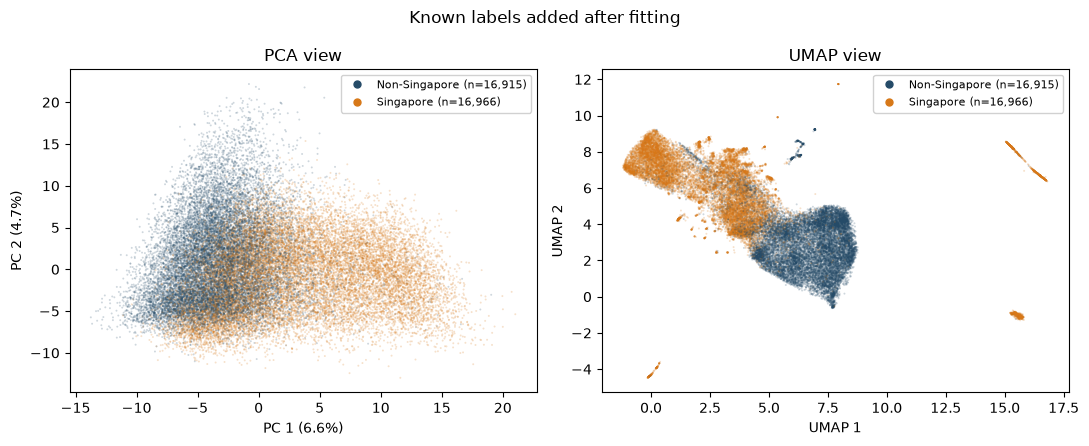

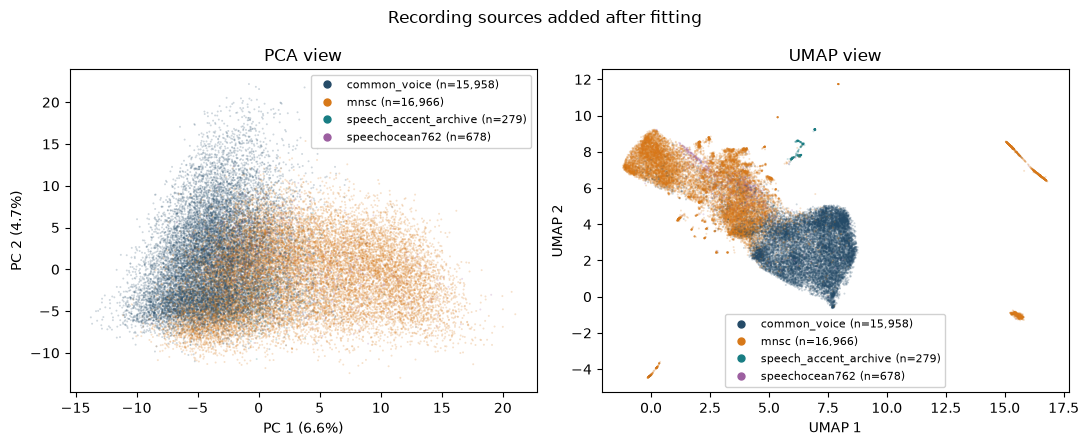

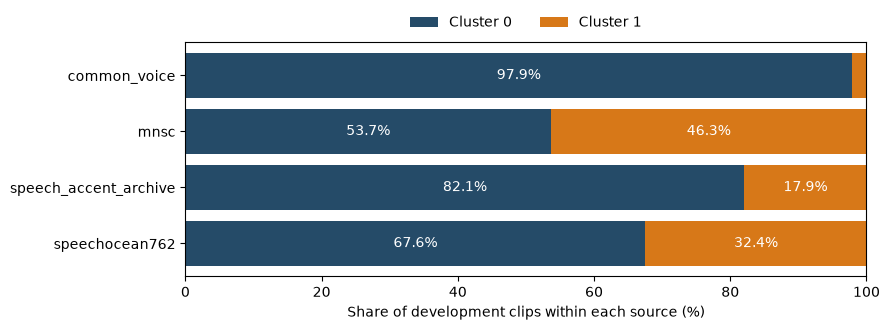

In [7]:
label_figure = draw_maps(assignments['known_label'], ['Non-Singapore', 'Singapore'],
    ['#254B68', '#D77818'], 'Known labels added after fitting', 'known_labels.png')
source_colors = ['#254B68', '#D77818', '#187D83', '#9C5FA0']
source_figure = draw_maps(assignments['source'], source_order, source_colors,
    'Recording sources added after fitting', 'recording_sources.png')

fig, ax = plt.subplots(figsize=(9, 3.4))
source_shares = cluster_sources.div(cluster_sources.sum(axis=1), axis=0) * 100
left = np.zeros(len(source_shares))
for cluster, color in zip([0, 1], ['#254B68', '#D77818']):
    values = source_shares[cluster].to_numpy()
    ax.barh(source_shares.index, values, left=left, color=color, label=f'Cluster {cluster}')
    for row, (value, offset) in enumerate(zip(values, left)):
        if value >= 8:
            ax.text(offset + value / 2, row, f'{value:.1f}%', color='white', ha='center', va='center')
    left += values
ax.set(xlim=(0, 100), xlabel='Share of development clips within each source (%)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
ax.invert_yaxis()
fig.tight_layout()
source_counts_figure = CHART_DIR / 'source_cluster_shares.png'
fig.savefig(source_counts_figure, dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 7 Check one mean embedding per speaker

The primary analysis weights clips equally. A speaker with more clips has more influence. As a small diagnostic, average the original 512-value embeddings for each development speaker. Refit scaling, PCA50, and K-means on those speaker means without labels. Each speaker then contributes one observation.

This check changes both the representation and the observation weights. Differences cannot be attributed to clip counts alone. It does not balance the numbers of speakers in the two classes, and it does not test new speakers. Keep it separate from the primary clip results.

In [8]:
phase_started = time.perf_counter()
speaker_ids, speaker_indices = np.unique(development['speaker_group'].to_numpy(), return_inverse=True)
speaker_clip_counts = np.bincount(speaker_indices)
speaker_means = np.zeros((len(speaker_ids), X.shape[1]), dtype=np.float32)
np.add.at(speaker_means, speaker_indices, X)
speaker_means /= speaker_clip_counts[:, None]
speaker_scaler, speaker_pca, speaker_reduced, speaker_kmeans, speaker_assignments_raw = fit_unsupervised(speaker_means)
speaker_sample = np.sort(np.random.default_rng(SETTINGS['seed']).choice(
    len(speaker_ids), min(SETTINGS['silhouette_max_clips'], len(speaker_ids)), replace=False))
speaker_silhouette = float(silhouette_score(speaker_reduced[speaker_sample], speaker_assignments_raw[speaker_sample]))

# Add metadata only after fitting this diagnostic.
speaker_metadata = development.groupby('speaker_group', sort=True).agg(
    label=('label', 'first'), source=('source', 'first'), split=('split', 'first')).loc[speaker_ids].reset_index()
speaker_metadata['clips_averaged'] = speaker_clip_counts
speaker_metadata['cluster'] = speaker_assignments_raw
speaker_metadata['known_label'] = speaker_metadata['label'].map({0: 'Non-Singapore', 1: 'Singapore'})
speaker_metadata.to_csv(OUTPUT_DIR / 'speaker_mean_assignments.csv', index=False)
speaker_label_ari = float(adjusted_rand_score(speaker_metadata['label'], speaker_assignments_raw))
speaker_label_counts = pd.crosstab(speaker_metadata['cluster'], speaker_metadata['known_label']).reindex(
    index=[0, 1], columns=['Non-Singapore', 'Singapore'], fill_value=0)
speaker_source_counts = pd.crosstab(speaker_metadata['source'], speaker_metadata['cluster']).reindex(columns=[0, 1], fill_value=0)
speaker_label_counts.to_csv(OUTPUT_DIR / 'speaker_mean_cluster_labels.csv')
speaker_source_counts.to_csv(OUTPUT_DIR / 'speaker_mean_cluster_sources.csv')
timing.append({'stage': 'speaker_mean_diagnostic', 'seconds': time.perf_counter() - phase_started})
print('Speaker means:', speaker_means.shape)
print('PCA variance retained:', f'{speaker_pca.explained_variance_ratio_.sum():.2%}')
print('Speaker-mean silhouette:', f'{speaker_silhouette:.4f}')
print('Speaker-mean accent ARI:', f'{speaker_label_ari:.4f}')
display(speaker_label_counts)
display(speaker_source_counts)

Speaker means: (8443, 512)
PCA variance retained: 58.85%
Speaker-mean silhouette: 0.0937
Speaker-mean accent ARI: -0.0614


known_label,Non-Singapore,Singapore
cluster,,
0,2728,16
1,4532,1167


cluster,0,1
source,,
common_voice,2711,4396
mnsc,16,1167
speech_accent_archive,0,44
speechocean762,17,92


## 8 Save the evidence and write the finding

Save the fitted unsupervised transforms, coordinates, assignments, protocol, audits, summary scores, package versions, and timings. These records support inspection and reruns. No classifier is trained or changed.

Interpret the results with the label table and source table together. A pure cluster need not cover most clips of that class. Good separation of K-means clusters also need not mean good separation of accents. A low accent ARI does not conflict with strong supervised SVM performance: K-means and a supervised classifier optimize different objectives.

In [9]:
assert len(assignments) == 33881
assert set(assignments['split']) == {'train', 'validation'}
assert not (set(assignments['clip_id']) & set(excluded_test['clip_id']))
assert not (set(assignments['speaker_group']) & set(excluded_test['speaker_group']))
assert int(cluster_labels['total_clips'].sum()) == len(assignments)
assert int(cluster_sources.to_numpy().sum()) == len(assignments)
assert int(speaker_label_counts.to_numpy().sum()) == len(speaker_ids)
assert all(np.isfinite(value) for value in [silhouette, label_ari, speaker_silhouette, speaker_label_ari])

joblib.dump({'scaler': scaler, 'pca': pca, 'kmeans': kmeans, 'settings': SETTINGS,
             'fit_clip_ids_sha256': audit['fit_clip_ids_sha256']}, OUTPUT_DIR / 'clip_unsupervised_pipeline.joblib')
joblib.dump({'scaler': speaker_scaler, 'pca': speaker_pca, 'kmeans': speaker_kmeans,
             'settings': SETTINGS}, OUTPUT_DIR / 'speaker_mean_unsupervised_pipeline.joblib')
np.savez_compressed(OUTPUT_DIR / 'development_coordinates.npz',
    clip_ids=assignments['clip_id'].to_numpy(dtype=str), pca=pca_xy, umap=umap_xy, clusters=clusters)

def table_records(frame):
    return json.loads(frame.reset_index().to_json(orient='records'))

report = {
    'status': 'completed', 'experiment': 'E3 development-only unsupervised exploration',
    'started_utc': started_utc, 'python': platform.python_version(), 'packages': packages,
    'settings': SETTINGS, 'settings_sha256': settings_sha256, 'input_audit': audit,
    'embedding_model': provenance['model'], 'encoder_revision': provenance['resolved_revision'],
    'recordings': len(assignments), 'speakers': len(speaker_ids), 'embedding_dimensions': X.shape[1],
    'pca_variance_retained': variance_retained,
    'silhouette_sample_clips': len(silhouette_indices), 'silhouette_score': silhouette,
    'accent_adjusted_rand_index': label_ari,
    'cluster_label_counts': table_records(cluster_labels),
    'cluster_source_counts': table_records(cluster_sources),
    'initialization_stability': json.loads(stability.to_json(orient='records')),
    'speakers_with_clips_in_both_clusters': speakers_in_both,
    'speaker_mean_check': {
        'speakers': len(speaker_ids),
        'pca_variance_retained': float(speaker_pca.explained_variance_ratio_.sum()),
        'silhouette_sample_speakers': len(speaker_sample), 'silhouette_score': speaker_silhouette,
        'accent_adjusted_rand_index': speaker_label_ari,
        'cluster_labels': table_records(speaker_label_counts),
        'cluster_sources': table_records(speaker_source_counts),
    },
    'limits': [
        'Exploratory development analysis, not held-out classification accuracy.',
        'An earlier all-clip exploration included the already evaluated study test set.',
        'All Singapore clips are MNSC, so source and class remain confounded.',
        'K=2 is an imposed question, not evidence that two natural groups exist.',
        'Silhouette uses a fixed sample; no inferential confidence interval is claimed.',
        'Initialization checks do not measure uncertainty under new speakers or sources.',
        'Speaker means change both representation and observation weights.',
        'UMAP display distances and islands are not a validated accent distance.',
    ],
}
sg_rich_cluster = int(cluster_labels['Singapore_share'].idxmax())
sg_share = float(cluster_labels.loc[sg_rich_cluster, 'Singapore_share'])
sg_coverage = float(cluster_labels.loc[sg_rich_cluster, 'Singapore'] / (assignments['label'] == 1).sum())
finding = (
    f'Cluster {sg_rich_cluster} contains {sg_share:.2%} Singapore clips, but includes only '
    f'{sg_coverage:.2%} of all development Singapore clips. The other Singapore clips are in the mixed cluster. '
    f'The silhouette ({silhouette:.4f}), accent ARI ({label_ari:.4f}), and label counts show overlap. '
    'The two imposed clusters do not reproduce the two accent labels.'
)
minimum_seed_ari = float(stability.loc[stability['seed'] != SETTINGS['seed'], 'ari_to_primary'].min())
speaker_finding = (
    f'The tested initializations give almost identical partitions (minimum ARI to the primary run: {minimum_seed_ari:.4f}). '
    f'The clip-level accent alignment does not persist in the speaker-mean check (accent ARI {speaker_label_ari:.4f}). '
    'Aggregation changes representation and observation weights together, so this does not identify a cause.'
)
report['finding'] = finding
report['sensitivity_finding'] = speaker_finding
report['seconds'] = time.perf_counter() - run_started
(OUTPUT_DIR / 'report.json').write_text(json.dumps(report, indent=2, default=int) + '\n')
timing.append({'stage': 'whole_notebook_before_final_save', 'seconds': report['seconds']})
pd.DataFrame(timing).to_csv(OUTPUT_DIR / 'timing.csv', index=False)

label_table = ['| Cluster | Non-Singapore | Singapore | Total | Singapore share |',
               '|---|---:|---:|---:|---:|']
for cluster, row in cluster_labels.iterrows():
    label_table.append(f"| {cluster} | {int(row['Non-Singapore']):,} | {int(row['Singapore']):,} | "
                       f"{int(row['total_clips']):,} | {row['Singapore_share']:.2%} |")
source_table = ['| Source | Cluster 0 clips | Cluster 1 clips | Distinct speakers |',
                '|---|---:|---:|---:|']
source_speakers = assignments.groupby('source')['speaker_group'].nunique()
for source, row in cluster_sources.iterrows():
    source_table.append(f'| {source} | {row[0]:,} | {row[1]:,} | {source_speakers[source]:,} |')

lines = [
    '# E3 Development-only unsupervised study', '',
    'Completed on 28 October 2026. This is a descriptive analysis, not a classification test.', '',
    f'Used {len(assignments):,} development clips from {len(speaker_ids):,} speakers. '
    'All 6,119 study test clips were excluded from fitting, plots, and metrics. '
    'Cache and manifest checks passed; there is no speaker overlap with the excluded test set.', '',
    'The earlier all-40,000-clip notebook is archived. Its exploration included the study test set. '
    'This revision does not restore test independence.', '',
    '## Procedure', '',
    'Verified frozen Whisper-base.en embeddings → standard scaling → PCA50 → K-means with two clusters. '
    'All fitting uses embeddings only. PCA uses the full SVD solver. K-means uses ten initializations and seed 42. '
    'The PCA width and cluster count were not selected from accent-label agreement. '
    'UMAP uses the same development PCA features only for display.', '',
    'PCA50 is an exploratory setting inherited from the earlier E3 run. It is separate from fusion PCA32.', '',
    '## Primary clip results', '',
    f'- PCA variance retained: **{variance_retained:.2%}**.',
    f'- Silhouette: **{silhouette:.4f}**, using {len(silhouette_indices):,} fixed sampled development clips.',
    f'- Accent adjusted Rand index after fitting: **{label_ari:.4f}**.', '',
    *label_table, '', *source_table, '',
    f'{speakers_in_both:,} speakers have clips in both clusters. Distinct speakers can therefore appear in both cluster totals.', '',
    '![Clusters](../outputs/e3_development_20261028/charts/clusters.png)', '',
    '![Known labels](../outputs/e3_development_20261028/charts/known_labels.png)', '',
    '![Source shares](../outputs/e3_development_20261028/charts/source_cluster_shares.png)', '',
    '## Sensitivity checks', '',
    f'Additional seeds 7 and 19 compare clustering with the primary seed, using no accent labels. '
    f'The minimum ARI to the primary partition is **{minimum_seed_ari:.4f}**. '
    'This checks starting conditions, not new-speaker uncertainty.', '',
    f'The separate speaker-mean analysis uses {len(speaker_ids):,} observations. '
    f'Its silhouette is {speaker_silhouette:.4f}; its accent ARI is {speaker_label_ari:.4f}. '
    'Aggregation changes both representation and observation weights. The class speaker counts remain unequal.', '',
    '## Interpretation and limits', '',
    finding, '', speaker_finding, '',
    'K-means imposes two groups. Inspect the label table for overlap and the source table for source effects. '
    'Do not describe either cluster as a validated Singapore-accent class. '
    'All Singapore clips are MNSC, so the data cannot distinguish accent from recording source. '
    'ARI and silhouette are not classification accuracy or evidence of performance on new sources. '
    'The analysis does not select or change the supervised classifier.', '',
    'The saved pipeline, assignments, coordinates, input audit, settings, versions, and timing are in '
    '`outputs/e3_development_20261028/`.', '',
]
RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)
RESULT_PATH.write_text('\n'.join(lines))
display(Markdown('\n'.join(lines[lines.index('## Primary clip results'):lines.index('## Sensitivity checks')])))
display(Markdown('**Observed finding:** ' + finding + '\n\n' + speaker_finding))
print('All integrity checks passed.')
print('Saved report:', RESULT_PATH)
print('Saved outputs:', OUTPUT_DIR)

## Primary clip results

- PCA variance retained: **59.68%**.
- Silhouette: **0.1272**, using 5,000 fixed sampled development clips.
- Accent adjusted Rand index after fitting: **0.1819**.

| Cluster | Non-Singapore | Singapore | Total | Singapore share |
|---|---:|---:|---:|---:|
| 0 | 16,308 | 9,108 | 25,416 | 35.84% |
| 1 | 607 | 7,858 | 8,465 | 92.83% |

| Source | Cluster 0 clips | Cluster 1 clips | Distinct speakers |
|---|---:|---:|---:|
| common_voice | 15,621 | 337 | 7,107 |
| mnsc | 9,108 | 7,858 | 1,183 |
| speech_accent_archive | 229 | 50 | 44 |
| speechocean762 | 458 | 220 | 109 |

1,135 speakers have clips in both clusters. Distinct speakers can therefore appear in both cluster totals.

![Clusters](../outputs/e3_development_20261028/charts/clusters.png)

![Known labels](../outputs/e3_development_20261028/charts/known_labels.png)

![Source shares](../outputs/e3_development_20261028/charts/source_cluster_shares.png)


**Observed finding:** Cluster 1 contains 92.83% Singapore clips, but includes only 46.32% of all development Singapore clips. The other Singapore clips are in the mixed cluster. The silhouette (0.1272), accent ARI (0.1819), and label counts show overlap. The two imposed clusters do not reproduce the two accent labels.

The tested initializations give almost identical partitions (minimum ARI to the primary run: 0.9999). The clip-level accent alignment does not persist in the speaker-mean check (accent ARI -0.0614). Aggregation changes representation and observation weights together, so this does not identify a cause.

All integrity checks passed.
Saved report: /home/mh/nusproj/singlish-whisper/results/E3_UNSUPERVISED_DEVELOPMENT_20261028.md
Saved outputs: /home/mh/nusproj/singlish-whisper/outputs/e3_development_20261028


## Use the result in the project report

The executed finding and tables above describe this development dataset. Record them together with the source and speaker limitations. Do not claim that two accents were discovered or that the clustering validates the classifier.

No favorable result is required to complete E3. Once these results are recorded, the next classification experiment is A1: refit acoustic feature selection on original training speakers and compare acoustic, Whisper-only, and fusion models with consistent tuning rules.